In [6]:
ICC = "/dcs/23/u5527350/3rdyearproject/results/ICC-512/All-ICC-Compiled-Tables.pickle"
DCC = "/dcs/23/u5527350/3rdyearproject/results/DCC-512/All-DCC-Compiled-Tables.pickle"
LTM = "/dcs/23/u5527350/3rdyearproject/results/LTM-512/All-LTM-Compiled-Tables.pickle"

In [7]:
import pickle
import pandas as pd
results = []
with open(ICC, "rb") as f:
    results.append(pickle.load(f))
with open(DCC, "rb") as f:
    results.append(pickle.load(f))
with open(LTM, "rb") as f:
    results.append(pickle.load(f))

# The config for this set of data
    datasets = [
        # (Label, Networkx Datastructure, Sampling Method, number of nodes to sample)
        ("Enron-MHDA-4096", enron_data.get_nx(), Sampling.mhda_sample, 4096),
        ("Enron-MHDA-1024", enron_data.get_nx(), Sampling.mhda_sample, 1024),
        #("Enron-MHRW-1024", enron_data.get_nx(), Sampling.mhrw_sample, 1024),
    ]
    heuristics = [
        ("Random", Heuristics.random_h),
        ("Degree", Heuristics.deg_h),
        ("Discount", Heuristics.deg_discount_h),
        ("Neighbour", Heuristics.mean_neighbour_deg_h),
        ("Betweeeness", Heuristics.betweenness_centrality_h),
        ("LocalClustering", Heuristics.local_clustering_coefficient_h),
        # (Name, Function)
    ]
    seed_sizes = [1, 2, 4, 8, 16, 32, 64, 128, 256, 512] 

In [8]:
ICC_N = results[0][4].iloc[::-1]
DCC_N = results[1][4].iloc[::-1]
LTM_N = results[2][4].iloc[::-1]
ICC_DD = results[0][5].iloc[::-1]
DCC_DD = results[1][5].iloc[::-1]
LTM_DD = results[2][5].iloc[::-1]
ICC_R = results[0][3].iloc[::-1]
DCC_R = results[1][3].iloc[::-1]
LTM_R = results[2][3].iloc[::-1]

print(ICC_N)

           dataset heuristic    n  start_coverage  start_coverage_std  \
0  Enron-MHDA-1024    Degree    1        0.000977                 0.0   
0  Enron-MHDA-1024    Degree    2        0.001953                 0.0   
0  Enron-MHDA-1024    Degree    4        0.003906                 0.0   
0  Enron-MHDA-1024    Degree    8        0.007812                 0.0   
0  Enron-MHDA-1024    Degree   16        0.015625                 0.0   
0  Enron-MHDA-1024    Degree   32        0.031250                 0.0   
0  Enron-MHDA-1024    Degree   64        0.062500                 0.0   
0  Enron-MHDA-1024    Degree  128        0.125000                 0.0   
0  Enron-MHDA-1024    Degree  256        0.250000                 0.0   
0  Enron-MHDA-1024    Degree  512        0.500000                 0.0   

   end_coverage  end_coverage_std  iterations  iterations_std  time_taken_ns  \
0      0.338957          0.041597   11.361328        1.861490   2.247470e+08   
0      0.339390          0.041691   

In [9]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import scienceplots
plt.style.use(['science', 'no-latex'])

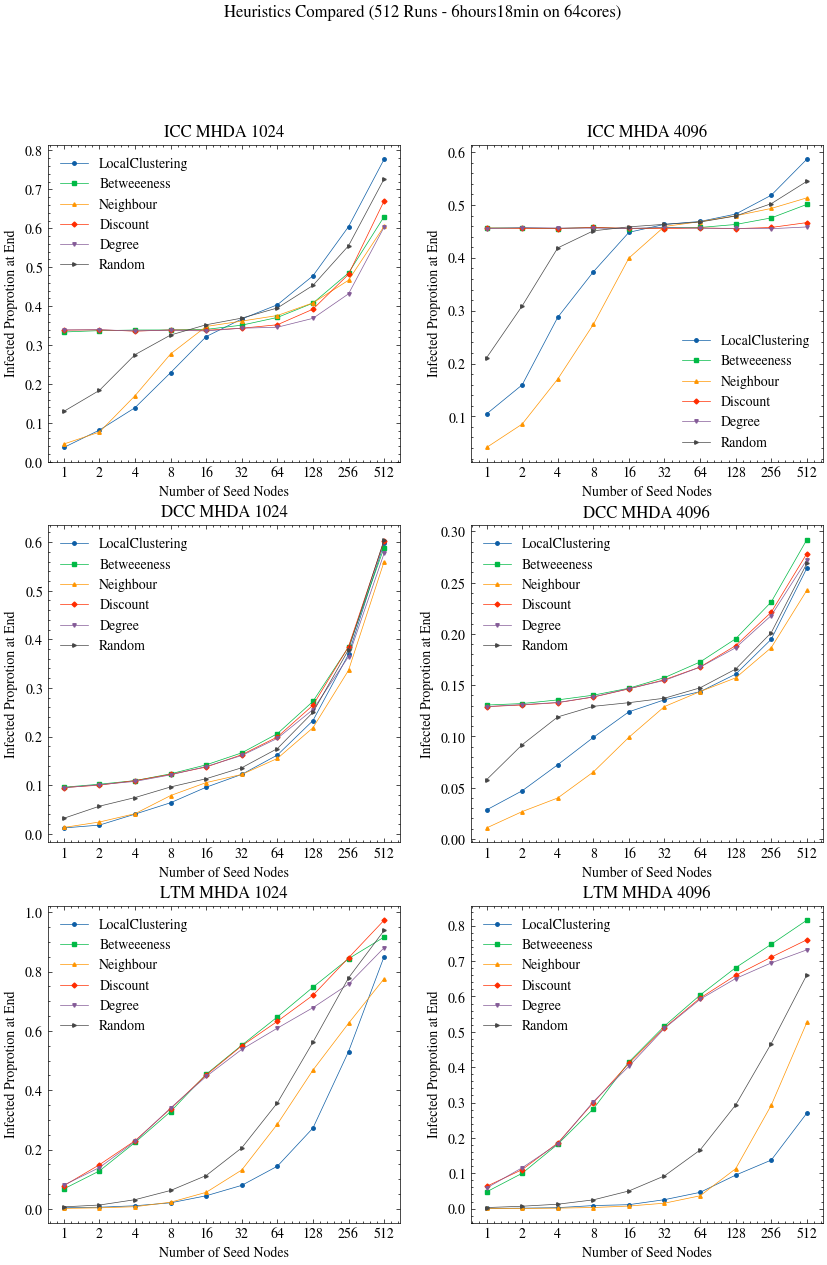

In [20]:
ICC_Sampled = [i for i in results[0] if i['dataset'].iloc[0] == 'Enron-MHDA-1024']
ICC_Unsampled = [i for i in results[0] if i['dataset'].iloc[0] != 'Enron-MHDA-1024']
DCC_Sampled = [i for i in results[1] if i['dataset'].iloc[0] == 'Enron-MHDA-1024']
DCC_Unsampled = [i for i in results[1] if i['dataset'].iloc[0] != 'Enron-MHDA-1024']
LTM_Sampled = [i for i in results[2] if i['dataset'].iloc[0] == 'Enron-MHDA-1024']
LTM_Unsampled = [i for i in results[2] if i['dataset'].iloc[0] != 'Enron-MHDA-1024']
markers =  ['o', 's', '^', 'D', 'v', '>', '<', 'p', '*', 'x']
plt.rcParams['figure.figsize'] = [10, 14]
fig, axs = plt.subplots(3,2)
fig.suptitle("Heuristics Compared (512 Runs - 6hours18min on 64cores)")
legends = []
for i, table in enumerate(ICC_Sampled):
    table = table.iloc[::-1]
    axs[0, 0].plot(table['n'].to_numpy(), table['end_coverage'], marker=markers[i % len(markers)],linewidth=0.5, markersize=2.5)
    legends.append(table['heuristic'].unique()[0])
    axs[0, 0].set_title("ICC MHDA 1024")
for i,table in enumerate(ICC_Unsampled):
    table = table.iloc[::-1]
    axs[0, 1].plot(table['n'].to_numpy(), table['end_coverage'],marker=markers[i % len(markers)],linewidth=0.5, markersize=2.5)
    legends.append(table['heuristic'].unique()[0])
    axs[0, 1].set_title("ICC MHDA 4096")
for i,table in enumerate(DCC_Sampled):
    table = table.iloc[::-1]
    axs[1, 0].plot(table['n'].to_numpy(), table['end_coverage'],marker=markers[i % len(markers)],linewidth=0.5, markersize=2.5)
    legends.append(table['heuristic'].unique()[0])
    axs[1, 0].set_title("DCC MHDA 1024")
for i,table in enumerate(DCC_Unsampled):
    table = table.iloc[::-1]
    axs[1, 1].plot(table['n'].to_numpy(), table['end_coverage'],marker=markers[i % len(markers)],linewidth=0.5, markersize=2.5)
    legends.append(table['heuristic'].unique()[0])
    axs[1, 1].set_title("DCC MHDA 4096")
for i,table in enumerate(LTM_Sampled):
    table = table.iloc[::-1]
    axs[2, 0].plot(table['n'].to_numpy(), table['end_coverage'],marker=markers[i % len(markers)],linewidth=0.5, markersize=2.5)
    legends.append(table['heuristic'].unique()[0])
    axs[2, 0].set_title("LTM MHDA 1024")
for i,table in enumerate(LTM_Unsampled):
    table = table.iloc[::-1]
    axs[2, 1].plot(table['n'].to_numpy(), table['end_coverage'],marker=markers[i % len(markers)],linewidth=0.5, markersize=2.5)
    legends.append(table['heuristic'].unique()[0])
    axs[2, 1].set_title("LTM MHDA 4096")
for ax in axs.flat:
    ax.set_xlabel("Number of Seed Nodes")
    ax.set_ylabel("Infected Proprotion at End")
    ax.legend(legends)
plt.show()
fig.savefig("early_hueristics_on_mhda_enron_2_sizes_all_models.png", format="png")

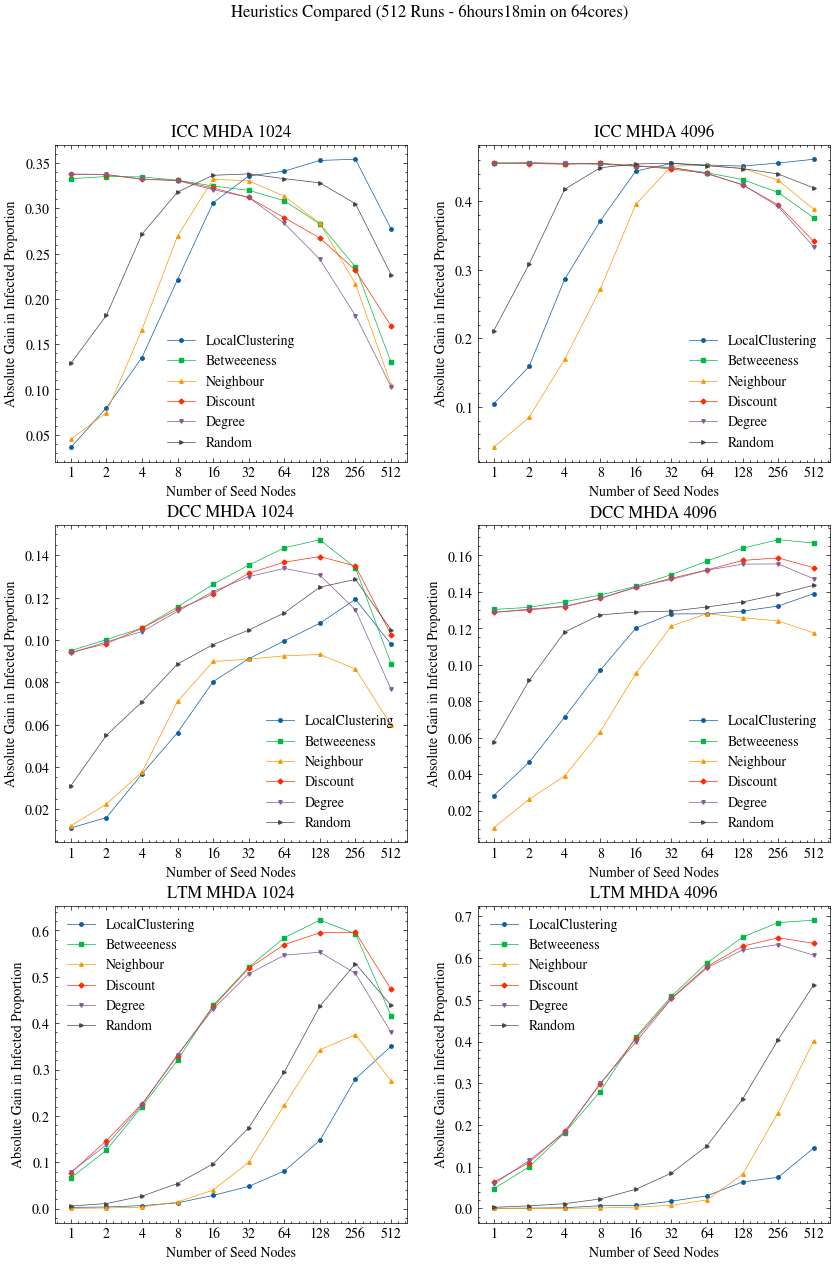

In [22]:
ICC_Sampled = [i for i in results[0] if i['dataset'].iloc[0] == 'Enron-MHDA-1024']
ICC_Unsampled = [i for i in results[0] if i['dataset'].iloc[0] != 'Enron-MHDA-1024']
DCC_Sampled = [i for i in results[1] if i['dataset'].iloc[0] == 'Enron-MHDA-1024']
DCC_Unsampled = [i for i in results[1] if i['dataset'].iloc[0] != 'Enron-MHDA-1024']
LTM_Sampled = [i for i in results[2] if i['dataset'].iloc[0] == 'Enron-MHDA-1024']
LTM_Unsampled = [i for i in results[2] if i['dataset'].iloc[0] != 'Enron-MHDA-1024']
plt.rcParams['figure.figsize'] = [10, 14]
fig, axs = plt.subplots(3,2)
fig.suptitle("Heuristics Compared (512 Runs - 6hours18min on 64cores)")
legends = []
for i, table in enumerate(ICC_Sampled):
    table = table.iloc[::-1]
    axs[0, 0].plot(table['n'].to_numpy(), table['end_coverage']-table['start_coverage'], marker=markers[i % len(markers)],linewidth=0.5, markersize=2.5)
    legends.append(table['heuristic'].unique()[0])
    axs[0, 0].set_title("ICC MHDA 1024")
for i, table in enumerate(ICC_Unsampled):
    table = table.iloc[::-1]
    axs[0, 1].plot(table['n'].to_numpy(), table['end_coverage']-table['start_coverage'], marker=markers[i % len(markers)],linewidth=0.5, markersize=2.5)
    legends.append(table['heuristic'].unique()[0])
    axs[0, 1].set_title("ICC MHDA 4096")
for i, table in enumerate(DCC_Sampled):
    table = table.iloc[::-1]
    axs[1, 0].plot(table['n'].to_numpy(), table['end_coverage']-table['start_coverage'], marker=markers[i % len(markers)],linewidth=0.5, markersize=2.5)
    legends.append(table['heuristic'].unique()[0])
    axs[1, 0].set_title("DCC MHDA 1024")
for i, table in enumerate(DCC_Unsampled):
    table = table.iloc[::-1]
    axs[1, 1].plot(table['n'].to_numpy(),table['end_coverage']-table['start_coverage'], marker=markers[i % len(markers)],linewidth=0.5, markersize=2.5)
    legends.append(table['heuristic'].unique()[0])
    axs[1, 1].set_title("DCC MHDA 4096")
for i, table in enumerate(LTM_Sampled):
    table = table.iloc[::-1]
    axs[2, 0].plot(table['n'].to_numpy(), table['end_coverage']-table['start_coverage'], marker=markers[i % len(markers)],linewidth=0.5, markersize=2.5)
    legends.append(table['heuristic'].unique()[0])
    axs[2, 0].set_title("LTM MHDA 1024")
for i, table in enumerate(LTM_Unsampled):
    table = table.iloc[::-1]
    axs[2, 1].plot(table['n'].to_numpy(), table['end_coverage']-table['start_coverage'], marker=markers[i % len(markers)],linewidth=0.5, markersize=2.5)
    legends.append(table['heuristic'].unique()[0])
    axs[2, 1].set_title("LTM MHDA 4096")
for ax in axs.flat:
    ax.set_xlabel("Number of Seed Nodes")
    ax.set_ylabel("Absolute Gain in Infected Proportion")
    ax.legend(legends)
plt.show()
fig.savefig("early_hueristics_on_mhda_enron_2_sizes_all_models_abs_delta.png", format="png")

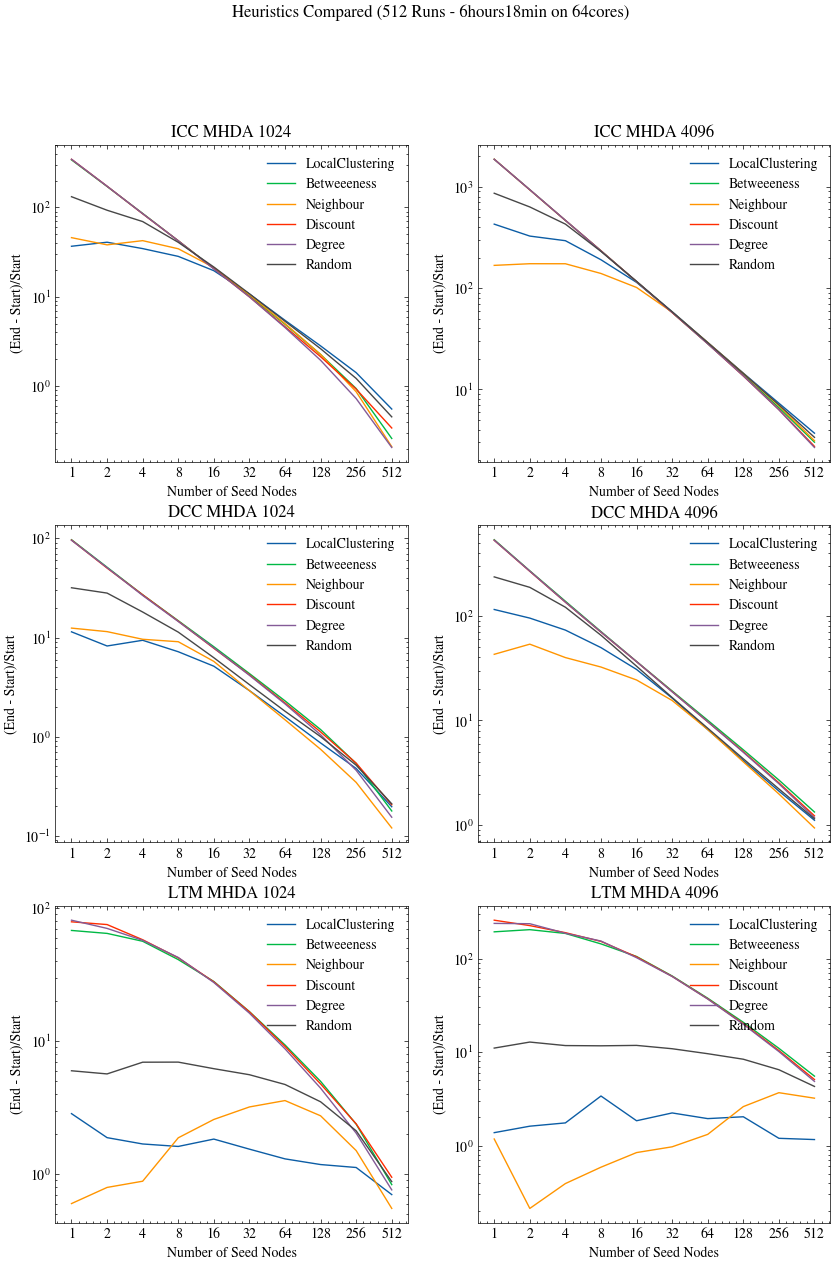

In [12]:
ICC_Sampled = [i for i in results[0] if i['dataset'].iloc[0] == 'Enron-MHDA-1024']
ICC_Unsampled = [i for i in results[0] if i['dataset'].iloc[0] != 'Enron-MHDA-1024']
DCC_Sampled = [i for i in results[1] if i['dataset'].iloc[0] == 'Enron-MHDA-1024']
DCC_Unsampled = [i for i in results[1] if i['dataset'].iloc[0] != 'Enron-MHDA-1024']
LTM_Sampled = [i for i in results[2] if i['dataset'].iloc[0] == 'Enron-MHDA-1024']
LTM_Unsampled = [i for i in results[2] if i['dataset'].iloc[0] != 'Enron-MHDA-1024']
plt.rcParams['figure.figsize'] = [10, 14]
fig, axs = plt.subplots(3,2)
fig.suptitle("Heuristics Compared (512 Runs - 6hours18min on 64cores)")
legends = []
for table in ICC_Sampled:
    table = table.iloc[::-1]
    axs[0, 0].plot(table['n'].to_numpy(), (table['end_coverage']-table['start_coverage'])/table['start_coverage'] )
    legends.append(table['heuristic'].unique()[0])
    axs[0, 0].set_title("ICC MHDA 1024")
    axs[0, 0].set_yscale('log')
for table in ICC_Unsampled:
    table = table.iloc[::-1]
    axs[0, 1].plot(table['n'].to_numpy(),  (table['end_coverage']-table['start_coverage'])/table['start_coverage'] )
    legends.append(table['heuristic'].unique()[0])
    axs[0, 1].set_title("ICC MHDA 4096")
    axs[0, 1].set_yscale('log')
for table in DCC_Sampled:
    table = table.iloc[::-1]
    axs[1, 0].plot(table['n'].to_numpy(),  (table['end_coverage']-table['start_coverage'])/table['start_coverage'] )
    legends.append(table['heuristic'].unique()[0])
    axs[1, 0].set_title("DCC MHDA 1024")
    axs[1, 0].set_yscale('log')
for table in DCC_Unsampled:
    table = table.iloc[::-1]
    axs[1, 1].plot(table['n'].to_numpy(), (table['end_coverage']-table['start_coverage'])/table['start_coverage'] )
    legends.append(table['heuristic'].unique()[0])
    axs[1, 1].set_title("DCC MHDA 4096")
    axs[1, 1].set_yscale('log')
for table in LTM_Sampled:
    table = table.iloc[::-1]
    axs[2, 0].plot(table['n'].to_numpy(), (table['end_coverage']-table['start_coverage'])/table['start_coverage'] )
    legends.append(table['heuristic'].unique()[0])
    axs[2, 0].set_title("LTM MHDA 1024")
    axs[2, 0].set_yscale('log')
for table in LTM_Unsampled:
    table = table.iloc[::-1]
    axs[2, 1].plot(table['n'].to_numpy(),  (table['end_coverage']-table['start_coverage'])/table['start_coverage'] )
    legends.append(table['heuristic'].unique()[0])
    axs[2, 1].set_title("LTM MHDA 4096")
    axs[2, 1].set_yscale('log')
for ax in axs.flat:
    ax.set_xlabel("Number of Seed Nodes")
    ax.set_ylabel("(End - Start)/Start")
    ax.legend(legends)
plt.show()
fig.savefig("example-plots")

In [13]:
# Significance
import scipy as sp

ModuleNotFoundError: No module named 'scipy'

In [ ]:
clustering = ICC_Sampled[0]
discount = ICC_Sampled[3]
random = ICC_Sampled[5]

In [ ]:
sp.stats.ttest_ind_from_stats(discount['end_coverage'], discount['end_coverage_std'], 512, random['end_coverage'], random['end_coverage_std'], 512)

In [ ]:
eigen_path = "/dcs/23/u5527350/3rdyearproject/results/eigen/All-ICC-Compiled-Tables.pickle"
LTM = "/dcs/23/u5527350/3rdyearproject/results/LTM-512/All-LTM-Compiled-Tables.pickle"
eigen = None
with open(eigen_path, "rb") as f:
    eigen = pickle.load(f)
eigen

In [ ]:
fig, ax = plt.subplots(1)
legends = []
for table in eigen:
    table = table.iloc[::-1]
    ax.plot(table['n'].to_numpy(), (table['end_coverage']))
    legends.append(table['heuristic'].unique()[0])
    ax.set_title("ICC MHDA 1024")
ax.legend(legends)
